<a href="https://colab.research.google.com/github/T1toh/30Days_of_SQL/blob/main/MODULE_6_%7C_LESSON_4_Regulatory_Implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **CAPSTONE REVIEW**
## MODULE 6 | LESSON 4: Regulatory Implementation

| | |
|:---|:---|
|**Reading Time** | 5h |
|**Prior Knowledge** | risk management fundamentals, regulatory frameworks (Basel III, Dodd-Frank), stress testing concepts, optimization theory, stochastic programming |
|**Keywords** | risk limits, calibration, regulatory reporting, TRACE, stress testing, SIFIs, capital requirements, multi-stage stochastic programming, cost of capital, cross-border regulation, regulatory arbitrage |

---

## **Introduction**

For the purposes of this lesson, regulatory implementation is what separates the theoretical elegance of financial regulation from the messy reality of making money while following the rules – and, therefore, what determines whether a financial institution thrives or merely survives.

A bit more precisely, we're concerned with how banks and other financial institutions transform abstract regulatory requirements into concrete operational procedures that satisfy regulators, protect against systemic risk, and still allow profitable business. The gap between what regulators write and what traders do is where fortunes are made or lost.

It pays to look at this challenge carefully. First, consider that every regulatory requirement costs money – not just in compliance expenses but in foregone opportunities. When leverage is capped at 2:1 for equity trading (why not 3:1? or 1.5:1?), entire classes of strategies become unprofitable. Note that we're not saying these strategies become impossible – they simply don't generate sufficient returns to justify the capital employed. This distinction matters enormously.

Think of regulatory implementation as translating between two languages that barely share vocabulary. Regulators speak in terms of systemic stability and stress scenarios. Traders speak in Sharpe ratios and basis points. Someone must build the bridge between these worlds – and that bridge must bear the weight of trillion-dollar balance sheets.

## **1. Risk Limits Design and Calibration**

### **1.1 The Architecture of Risk Limits**

Banks are allowed to use internal models for stress testing, but here's the catch – these models need validation so extensive that building them becomes a competitive advantage in itself. Surprisingly, many institutions discover that the validation process teaches them more about their risks than the models themselves.

Think of risk limits as a Russian doll of constraints. The outermost doll represents enterprise-wide limits – perhaps a \$100 million Value-at-Risk limit. Inside nest smaller dolls: business lines, trading desks, individual traders. But unlike Russian dolls, these limits don't sum neatly (why should they?). Diversification means a fixed income desk with a \$30 million limit and an equity desk with \$40 million might together generate only \$55 million in risk.

The architecture must be both rigid and flexible – rigid enough to prevent catastrophic losses, flexible enough to allow profitable trading. Excessive rigidity prevents profitable opportunities, while insufficient constraints expose the institution to unacceptable risks. Neither makes money consistently.

### **1.2 Calibration Methodologies**

Calibration is where mathematics meets psychology. You can calculate optimal limits using historical simulation, Monte Carlo methods, or copula-based models. But the number that emerges from your model isn't the number you'll implement – human judgment intervenes at every step.

Consider credit risk limits. The mathematics tells you default probabilities, loss-given-default, and correlation matrices. It doesn't tell you that your board gets nervous when commercial real estate exposure exceeds 300% of capital (even if the math says 350% is safe). Nor does it capture that your best credit analyst has a sixth sense for detecting fraud that no model replicates.

It pays to examine how different institutions approach calibration. A retail bank might set limits based on decades of mortgage default data. An investment bank can't – their exotic derivatives didn't exist decades ago. One relies on statistical confidence; the other on stress testing and imagination.

### **1.3 Dynamic Adjustment and Backtesting**

Static limits become ineffective as market conditions evolve. Markets evolve, correlations break down, and yesterday's conservative limit becomes today's reckless exposure. The question isn't whether to adjust limits – it's how quickly you can adjust without creating chaos.

Backtesting provides the reality check. If your 99% VaR limit breaches more than three times per year, something's wrong (do the math – why three?). But backtesting only tells you about the past. The future might be different – correction, the future will be different.

Note that dynamic adjustment creates its own risks. Traders hate moving targets. If limits change too frequently, they'll either ignore them or stop taking any risk at all. You need adjustment rules that are responsive but predictable – another contradiction to reconcile.

### What you’re about to code 🔍  
In the notebook that follows, we will **validate a 99 % one-day Value-at-Risk (VaR) model for the S&P 500** using three complementary statistical tools that supervisors rely on:

1. **Unconditional–coverage (UC) test — Kupiec (1995)**  
   The model states that the probability of a daily loss exceeding VaR is $p=1-\alpha=0.01$.  
   After $T$ trading days we observe $x$ exceptions.  The null hypothesis  
   $$H_0:\; \Pr(\text{exception}) = p$$  
   is tested with the likelihood-ratio statistic

   $$
   LR_{\text{uc}} \;=\; -2\ln\!\left[\frac{(1-p)^{\,T-x}p^{\,x}}{(1-\hat p)^{\,T-x}\hat p^{\,x}}\right],  
   \;\; \hat p = \tfrac{x}{T},
   $$

   which is asymptotically $\chi^{2}_{(1)}$.  Rejecting $H_0$ means the model **over- or under-estimates risk on average**.

2. **Independence test — Christoffersen (1998)**  
   Even if the average coverage is correct, **violations may cluster** (bad news) or be too evenly spaced (good luck).  
   Let $N_{ij}$ count transitions from state $i$ today to $j$ tomorrow, $i,j\in\{0,1\}$ (0 =no breach, 1 = breach).  
   Under  
   
   $$
   H_0:\; \Pr(X_t=1\mid X_{t-1}=0)=\Pr(X_t=1\mid X_{t-1}=1)=\hat p,
   $$  
   
   the likelihood-ratio statistic

   $$
   LR_{\text{ind}} \;=\; -2\ln\!\left[\frac{(1-\hat p)^{N_{00}+N_{10}}\hat p^{N_{01}+N_{11}}}                               {(1-\hat\pi_{01})^{N_{00}}\hat\pi_{01}^{{01}}                                (1-\hat\pi_{11})^{N_{10}}\hat\pi_{11}^{N_{11}}}\right]
   $$  

   (with $\hat\pi_{01}=N_{01}/(N_{00}+N_{01})$, $\hat\pi_{11}=N_{11}/(N_{10}+N_{11})$) is also $\chi^{2}_{(1)}$.  
   Rejecting $H_0$ signals **serial dependence in exceptions**.

3. **Basel traffic-light framework (1996)**  
   Supervisors keep a moving 250-day window and simply **count breaches**:  
   *Green* $(0\!-\!4)$, *Yellow* $(5\!-\!9)$ or *Red* $(\ge10)$ days.  
   Crossing into Yellow/Red increases the bank’s market-risk capital multiplier.

Together, $LR_{\text{uc}}$, $LR_{\text{ind}}$, and the colour-band plot give a **360° view of model accuracy and stability**.

**Pre-read**  
*Zhang & Nadarajah (2017), Sections 2.1–2.3, 2.11–2.12 & 2.14* provide an overview, intuition and further references for these tests.

In [1]:
# Imports
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy import stats
import warnings, datetime as dt
warnings.filterwarnings("ignore")

plt.style.use("default")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11

# Download prices, build daily log-returns
ticker = "^GSPC"
start  = "2010-01-01"
end    = dt.date.today().isoformat()       # makes notebook evergreen

#price   = yf.download(ticker, start=start, end=end, progress=False)["Close"]
price = pd.read_csv("/content/GSPC_prices.csv", index_col = "Date", parse_dates = True)
returns = np.log(price).diff().dropna()
returns.name = "log_ret"

print(f"Sample: {returns.index[0].date()} → {returns.index[-1].date()}  "
      f"({len(returns):,} observations)")



Sample: 2010-01-05 → 2025-08-01  (3,918 observations)


In [2]:
# Rolling historical 99 % VaR  &  exception flags
conf   = 0.99
h      = 250                               # 1 trading year
VaR    = (-returns.rolling(h).quantile(1-conf)).dropna()

# align, build DataFrame
df = pd.concat((returns, VaR), join = "inner", axis = 1, keys=['ret', 'VaR']).dropna()
df.columns = df.columns.droplevel(1)
df["loss"]       = -df["ret"]
df["exception"]  = (df["loss"] > df["VaR"]).astype(int)
df["roll_exc"]   = df["exception"].rolling(h).sum()

print(f"Mean 99 % VaR: {df['VaR'].mean():.4f}  ({df['VaR'].mean()*100:.2f} %)")
print(f"Total exceptions: {df['exception'].sum()}  "
      f"≈ {df['exception'].mean()*100:.2f} %")


Mean 99 % VaR: 0.0291  (2.91 %)
Total exceptions: 53  ≈ 1.44 %


In [3]:
# Kupiec (coverage) and Christoffersen (independence) tests
p_exp = 1 - conf
T     = len(df)
x     = int(df["exception"].sum())

# Kupiec LR — with edge-case guards
if x == 0:
    LR_uc = -2 * T * np.log(1 - p_exp)
elif x == T:
    LR_uc = -2 * T * np.log(p_exp)
else:
    p_obs = x / T
    LR_uc = -2 * ( x*np.log(p_exp/p_obs) +
                   (T-x)*np.log((1-p_exp)/(1-p_obs)) )

p_uc = 1 - stats.chi2.cdf(LR_uc, df=1)

# Christoffersen 1-lag independence test
exc = df["exception"]
n00 = ((exc.shift(1)==0)&(exc==0)).sum()
n01 = ((exc.shift(1)==0)&(exc==1)).sum()
n10 = ((exc.shift(1)==1)&(exc==0)).sum()
n11 = ((exc.shift(1)==1)&(exc==1)).sum()

pi_01 = n01/(n00+n01) if n00+n01 else 0
pi_11 = n11/(n10+n11) if n10+n11 else 0
pi    = (n01+n11)/(n00+n01+n10+n11)

if 0 < pi_01 < 1 and 0 < pi_11 < 1 and 0 < pi < 1:
    LR_ind = -2 * ( np.log((1-pi)**(n00+n10) * pi**(n01+n11)) -
                    np.log((1-pi_01)**n00 * pi_01**n01 *
                           (1-pi_11)**n10 * pi_11**n11) )
else:
    LR_ind = 0                                # no clustering info

p_ind = 1 - stats.chi2.cdf(LR_ind, df=1)


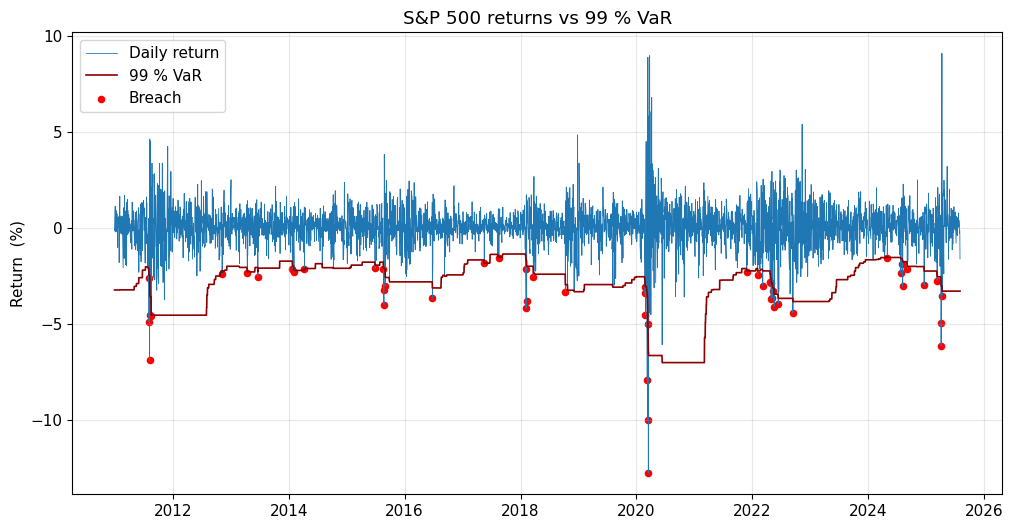

In [4]:
# returns vs VaR with breach dots
fig, ax = plt.subplots()
ax.plot(df.index, df["ret"]*100, lw=0.6, label="Daily return")
ax.plot(df.index, -df["VaR"]*100, c="darkred", lw=1.2, label="99 % VaR")
ax.scatter(df.index[df["exception"]==1],
           df.loc[df["exception"]==1, "ret"]*100,
           c="red", s=20, label="Breach")
ax.set_title("S&P 500 returns vs 99 % VaR")
ax.set_ylabel("Return  (%)")
ax.grid(alpha=.3)
ax.legend()
plt.show()


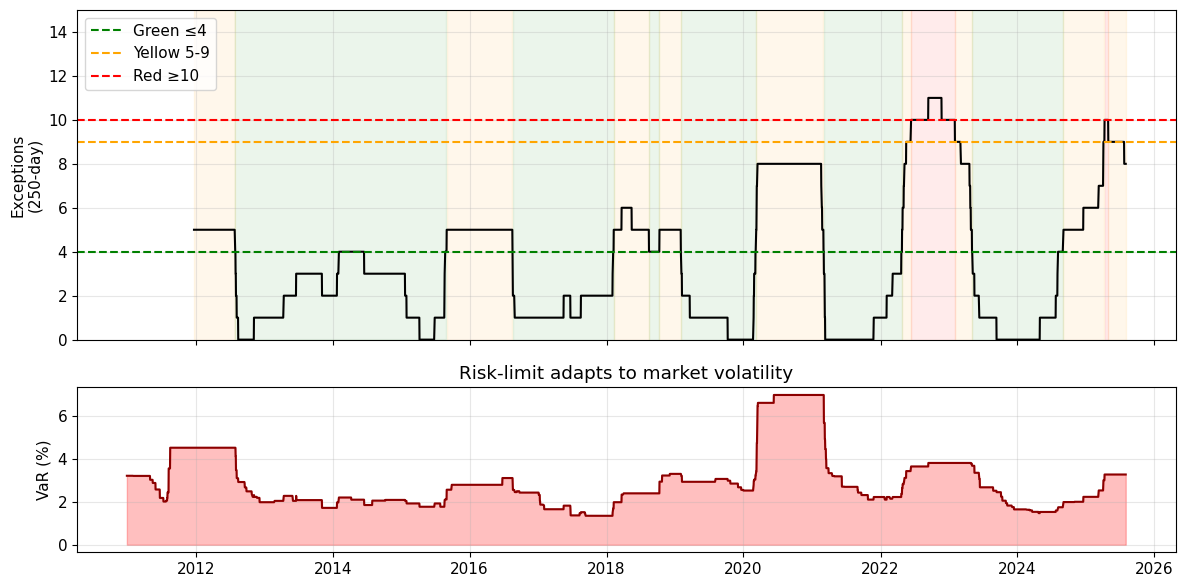

In [5]:
# 6 rolling 250-day exception count + traffic-light shading + VaR level
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, height_ratios=[2,1])

# top panel: exception count
ax1.plot(df.index, df["roll_exc"], c="black", lw=1.5)
ax1.axhline(4,  c="green",  ls="--", label="Green ≤4")
ax1.axhline(9,  c="orange", ls="--", label="Yellow 5-9")
ax1.axhline(10, c="red",    ls="--", label="Red ≥10")

# shading by zone
g = df["roll_exc"] <= 4
y = (df["roll_exc"]>4) & (df["roll_exc"]<=9)
r = df["roll_exc"] > 9
ax1.fill_between(df.index, 0, 15, where=g, alpha=.08, color="green")
ax1.fill_between(df.index, 0, 15, where=y, alpha=.08, color="orange")
ax1.fill_between(df.index, 0, 15, where=r, alpha=.08, color="red")

ax1.set_ylabel("Exceptions\n(250-day)")
ax1.set_ylim(0, 15)
ax1.legend()
ax1.grid(alpha=.3)

# bottom panel: VaR level evolution
ax2.plot(df.index, df["VaR"]*100, c="darkred")
ax2.fill_between(df.index, 0, df["VaR"]*100, alpha=.25, color="red")
ax2.set_ylabel("VaR (%)")
ax2.set_title("Risk-limit adapts to market volatility")
ax2.grid(alpha=.3)

plt.tight_layout()
plt.show()


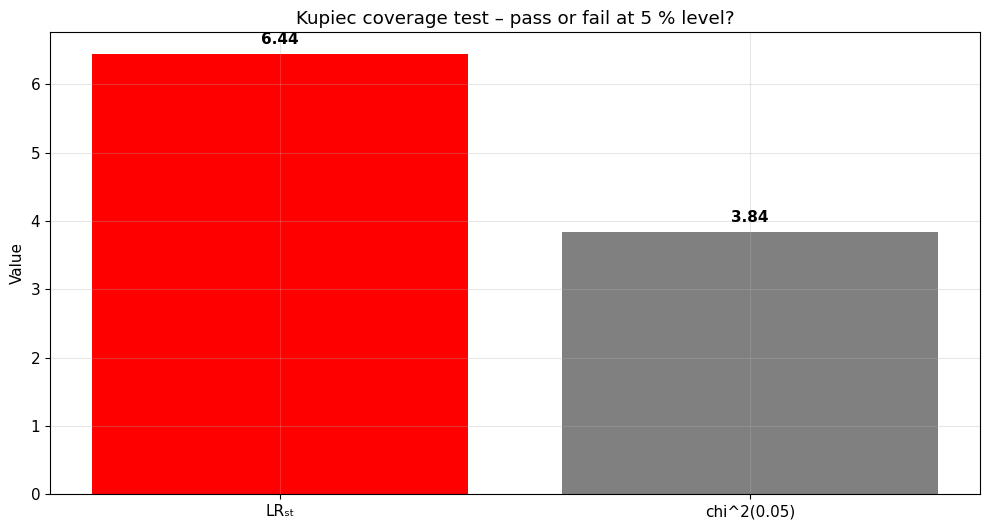

In [6]:
# Kupiec LR vs chi^2 critical
crit = stats.chi2.ppf(0.95, df=1)

fig, ax = plt.subplots()
bars = ax.bar(["LR\u209B\u209C", "chi^2(0.05)"], [LR_uc, crit],
              color=["red" if LR_uc>crit else "green", "grey"])
for b, v in zip(bars, [LR_uc, crit]):
    ax.text(b.get_x()+b.get_width()/2, v+0.1, f"{v:.2f}",
            ha="center", va="bottom", fontweight="bold")
ax.set_ylabel("Value")
ax.set_title("Kupiec coverage test – pass or fail at 5 % level?")
ax.grid(alpha=.3)
plt.show()


In [7]:
# Summary
zones = df["roll_exc"].apply(lambda z: "Green" if z<=4 else
                                          ("Yellow" if z<=9 else "Red"))
zone_counts = zones.value_counts()
zone_pct    = (zone_counts / len(df) * 100).round(1)

summary = {
    "Observations"           : T,
    "Exceptions"             : x,
    "Observed exc. rate"     : round(x / T, 4),
    "Expected exc. rate"     : round(p_exp, 4),
    "Kupiec LR"              : round(LR_uc, 2),
    "Kupiec p-value"         : round(p_uc, 4),
    "Kupiec verdict"         : "REJECT" if LR_uc > crit else "OK",
    "Christoffersen LR"      : round(LR_ind, 2),
    "Christoffersen p-value" : round(p_ind, 4),
    "Christoffersen verdict" : "REJECT" if LR_ind > crit else "OK",
    "Green days"             : zone_counts.get("Green", 0),
    "Green %"                : zone_pct.get("Green", 0),
    "Yellow days"            : zone_counts.get("Yellow", 0),
    "Yellow %"               : zone_pct.get("Yellow", 0),
    "Red days"               : zone_counts.get("Red", 0),
    "Red %"                  : zone_pct.get("Red", 0)
}

summary_df = pd.DataFrame(summary, index=["Value"]).T
summary_df


,Value
Observations,3669
Exceptions,53
Observed exc. rate,0.0144
Expected exc. rate,0.01
Kupiec LR,6.44
Kupiec p-value,0.0112
Kupiec verdict,REJECT
Christoffersen LR,20.07
Christoffersen p-value,0.0
Christoffersen verdict,REJECT


**Reading the outcome**  

The notebook produced **$x=53$ exceptions out of $T=3\,669$ observations**, an empirical breach rate of

$$
\hat p=\frac{53}{3\,669}\approx 1.44\%\;>\;p=1\%,
$$

so the VaR model **under-estimates tail risk**.

* **Unconditional-coverage test:**  
  
  $$
  LR_{\text{uc}} = 6.44 \;>\; \chi^{2}_{0.95}(1)=3.84 \;\Longrightarrow\; \text{reject }H_0.
  $$  

  Statistically, the model’s coverage is too low: we should have seen $\approx 37$ breaches, not $53$.

* **Independence test:**  
  
  $$
  LR_{\text{ind}} = 20.07 \;>\; 3.84 \;\Longrightarrow\; \text{reject independence}.
  $$  
  
  Exceptions arrive in **clusters** (notably in 2011, March 2020, and 2022), confirming the intuition that market stress is persistent.

* **Basel traffic-light:**  
  In the rolling 250-day window the process spent  
  *Green* $57\%$, *Yellow* $32\%$, *Red* $11\%$ of the time.  
  Whenever it entered Yellow/Red the bank would face higher market-risk capital multipliers.

These results are **typical for equity indices**: heavy-tailed returns and volatility clustering make a plain historical 99 % VaR too optimistic.  Students have therefore seen (i) how formal tests quantify that shortfall, (ii) why regulators embed simple count rules, and (iii) how quickly capital costs can rise when a VaR model drifts out of tune.  Possible next steps—left as exercises—include switching to an EWMA VaR or expected shortfall model and re-running the same back-tests to assess improvement.


## **2. Regulatory Reporting Requirements**

### **2.1 TRACE and Market Transparency**

TRACE requires bond trades to be reported within 15 minutes – a requirement that sounds simple until you try to implement it. Consider what happens in those 15 minutes: capture trade details, validate data, enrich with regulatory fields, handle exceptions, maintain audit trails, and transmit to TRACE. Miss the deadline and face fines. Rush the process and report errors that trigger investigations.

The 15-minute window has transformed bond trading more profoundly than any pricing model. Previously, large trades could hide in darkness for hours. Now they're visible almost instantly – turning information asymmetry from a profit source into a compliance risk.

Think of TRACE as forced transparency in a market that profited from opacity. Like requiring auction participants to disclose their bids immediately after each round – it fundamentally alters market dynamics and information asymmetries. Smart players adapt by trading smaller clips or using more complex strategies. Others simply exit the game.

### **2.2 Comprehensive Regulatory Reporting Frameworks**

Every financial institution faces a complex web of reporting requirements with overlapping jurisdictions and conflicting definitions. Call Reports, FR Y-9C, FFIEC 009, Basel III reports, Volcker metrics – each with different definitions, calculations, and deadlines. The same loan might be classified differently in five reports (why? Because regulators don't talk to each other).

The real challenge isn't producing reports – it's ensuring consistency when reports conflict. Your Basel III report says you have \$100 billion in risk-weighted assets. Your stress test submission says \$105 billion. Both numbers are correct under their respective methodologies. Try explaining that to a skeptical examiner.

Note that comprehensive doesn't mean comprehensible. Large banks employ armies of people whose sole job is translating between different reporting frameworks. It's like being forced to file your taxes in five different accounting systems simultaneously – possible, but painfully expensive.

### **2.3 Data Governance and Quality Control**

Within financial firms, everything is recorded – emails, chats, phone calls, even the pauses between keystrokes. This isn't paranoia; it's regulation. But recording is easy. Finding the right communication during an investigation? That's where fortunes are spent.

Data governance sounds boring until you face a regulatory inquiry. "Show us all communications about trade X from date Y" seems simple. Then you discover trade X was called six different names across eight systems, date Y falls during a system migration, and half your traders used Bloomberg chat while the other half used Reuters.

Quality control becomes existential. Bad data doesn't just risk fines – it blinds you to risks. Imagine flying a plane where half the instruments show incorrect readings. You might land safely, but why take the chance?

## **3. Impact of Regulation on Trading Strategies**

### **3.1 Leverage Constraints and Strategy Design**

As we've seen, leverage for stock trading is capped at 50% for most investors – a number that seems arbitrary until you understand its history. Like many regulations, it reflects responses to historical crises that may not align with current market realities. But arbitrary or not, it shapes every equity strategy.

Consider a statistical arbitrage strategy generating 5% returns with 10% volatility. Boring, right? Add 2:1 leverage and suddenly you're looking at 10% returns (minus financing). But what if optimal leverage is 4:1? Too bad – find another strategy or another asset class.

The constraint creates strange distortions. You can buy a house with 20% down (5:1 leverage) but can only leverage stocks 2:1. No wonder financial engineering thrives – it's regulatory arbitrage dressed in mathematical sophistication.

### **3.2 Market Making and Proprietary Trading Restrictions**

The Volcker Rule tried to separate market making from proprietary trading – like trying to separate breathing from living. Every market-making trade involves taking risk. Every position held overnight could be called proprietary. The boundary exists only in regulatory imagination.

Banks now prove their market-making intent through metrics that would puzzle their best traders. Inventory aging analysis, customer-facing ratios, spread capture metrics – none capture the market maker's essential function: providing liquidity when others won't.

Note the perverse result. Algorithms now exit profitable positions not because markets turned, but because holding longer would breach regulatory metrics. It's like forcing a chef to cook with a stopwatch – possible, but hardly optimal.

### **3.3 Stress Testing and Strategy Resilience**

Stress tests have become the final arbiter of acceptable strategies. It's not enough to make money in normal markets – you must survive scenarios where everything goes wrong simultaneously. (But when has everything ever gone wrong in exactly the way regulators imagine?)

This requirement has birthed a new breed of strategies: profitable enough to pursue, boring enough to pass stress tests. High Sharpe ratios matter less than shallow drawdowns. Innovation takes a backseat to predictability.

The irony is palpable. Stress tests designed to prevent systemic risk might be creating it – by forcing everyone into similar "safe" strategies. When the next crisis arrives, widespread adoption of similar 'safe' strategies may create new forms of systemic risk concentration.

## **4. Cross-Border Regulatory Issues**

### **4.1 Regulatory Arbitrage and Harmonization**

Finance flows like water, finding the lowest regulatory point. But unlike water, it leaves profits behind. This is regulatory arbitrage – structuring transactions to exploit differences between jurisdictions. It's not illegal; it's inevitable.

Consider derivatives regulation. Dodd-Frank says one thing, EMIR another, and Asian regulators something else entirely. The same swap might require different margins, reporting, and capital depending on where you book it. Guess what? It gets booked where it's cheapest.

Harmonization sounds wonderful in theory. In practice, it's like asking countries to adopt the same tax code. Every jurisdiction wants harmonization – on their terms. The result is harmonized discord, with enough differences to keep lawyers employed for generations.

### **4.2 Extraterritorial Application**

U.S. regulations follow U.S. banks everywhere – demonstrating the extensive reach of extraterritorial regulatory jurisdiction. A derivative traded in London between two European counterparties might still fall under Dodd-Frank if a U.S. bank guarantees it, illustrating the broad scope of extraterritorial application.

This creates compliance nightmares. Imagine following two sets of rules that directly contradict each other. U.S. law says report the trade immediately. European privacy law says you can't. What do you do? Usually, you hire lawyers and hope for the best.

Note that extraterritorial reach works both ways. European sustainability regulations now affect U.S. banks operating in Europe. Asian data localization rules trap information behind digital borders. Every country exports its regulations along with its capital.

### **4.3 Regulatory Coordination in Crisis**

When the next crisis hits, regulators must coordinate across borders in real-time—a challenge that existing frameworks may not adequately address. If Bank A in New York owes Bank B in London who owes Bank C in Tokyo, whose rules apply when someone defaults?

The machinery exists – crisis management groups, information sharing agreements, coordinated stress tests. But machinery and execution are different things. It's like having a fire drill where everyone speaks different languages and uses different equipment.

Resolution planning adds another layer of complexity. Living wills must contemplate cross-border breakups that respect local bankruptcy laws, creditor hierarchies, and political realities. It's planning for a disaster where the rules change mid-catastrophe.

## **5. Computational Methods: Multi-Stage Stochastic Programming Under Regulatory Constraints**

### **5.1 Problem Formulation**

Consider the challenge of managing a pension fund. You must generate returns to pay retirees, maintain funding ratios to satisfy regulators, and survive stress tests that assume the world ends tomorrow. Multi-stage stochastic programming offers a framework – though framework sounds too simple for what's really a mathematical war game.

The formulation looks elegant on paper:
$$\max E\left[\sum_{t=1}^{T} \beta^t U(W_t) - \lambda \sum_{t=1}^{T} P_t(V_t)\right]$$

But elegance hides complexity. Each variable represents thousands of decisions, constraints encode millions of regulatory requirements, and the expectation operates over scenarios that include your worst nightmares.

It pays to think of this as chess where rules change mid-game. Today's optimal move might be illegal tomorrow if regulations shift. You're optimizing not just over market uncertainty but regulatory uncertainty – a far nastier beast.

### **5.2 Scenario Generation and Reduction**

Scenarios are stories with numbers. Market scenarios tell tales of crashes and booms. Regulatory scenarios imagine new rules, tighter constraints, and zealous enforcement. Together they create a possibility space vast enough to break any computer.

The curse of dimensionality isn't just computational – it's conceptual. How do you generate scenarios for regulations that don't exist yet? How do you model correlation between market stress and regulatory response? These factors tend to be positively correlated, with regulatory constraints typically tightening during periods of market distress.

Scenario reduction becomes an art. Keep too many and computation becomes impossible. Keep too few and you miss the scenario that kills you. It's like packing for a trip to an unknown destination with uncertain weather – you can't bring everything, but leave out the wrong item and you're miserable.

### **5.3 Solution Algorithms and Implementation**

Solving these problems requires computationally intensive algorithms that challenge even advanced computing infrastructure. Benders decomposition, progressive hedging, nested decomposition – each name hides months of implementation pain and numerical devils in the details.

The real challenge isn't solving the problem once – it's solving it repeatedly as conditions change. Markets move, regulations evolve, and your optimization from last month becomes today's compliance violation. You need solutions robust enough to survive reality.

Note that implementation separates theory from practice. Your elegant algorithm might solve toy problems beautifully. Scale it to real portfolios with thousands of assets and hundreds of constraints? That's when numerical stability becomes as important as theoretical correctness. Many beautiful algorithms have died on the rocks of practical implementation.

## **6. Cost of Capital and Regulations**

### **6.1 Direct Capital Costs**

SIFIs face substantial regulatory capital requirements that significantly impact their cost structure. G-SIB surcharges, countercyclical buffers, stress test buffers – each sounds reasonable in isolation. Stack them together and you're holding capital that could otherwise generate returns.

The math is straightforward but painful. Hold an extra 2% capital buffer when equity costs 10% and debt costs 2%? That's 16 basis points of drag on your entire balance sheet. On a trillion dollars in assets, this represents $1.6 billion in annual opportunity costs, illustrating the substantial economic impact of regulatory capital requirements.

But direct costs are just the beginning. Capital trapped in buffers can't be deployed for profitable trades. It's like being forced to keep half your army in reserve – prudent perhaps, but hardly the path to victory.

### **6.2 Operational and Compliance Costs**

Large banks spend billions on regulatory compliance – enough to run small countries. Technology infrastructure, compliance officers, model validation teams, internal auditors – it's a standing army that produces no revenue, only protection from penalties.

The numbers are staggering. JPMorgan employs over 43,000 people in compliance and control functions. That's larger than many companies' entire workforce. Each person costs approximately $200,000 fully loaded, representing a substantial aggregate expense.

Technology costs pile on top. Real-time risk systems, regulatory reporting platforms, communication surveillance – each system costs millions to build and more to maintain. It's like paying for insurance that never pays out, only prevents disasters you hope never happen.

### **6.3 Strategic Costs and Opportunity Costs**

Here's what really hurts: the opportunities foregone. That leveraged strategy you can't pursue. The emerging market you can't enter due to regulatory complexity. The innovation stifled by compliance concerns. These costs don't appear on financial statements but they're real as taxes.

Consider a concrete example. Pre-crisis, many banks ran profitable strategies leveraging AAA-rated securities 10:1 or more. Post-crisis leverage limits killed these strategies. The banks survived, but the profits vanished forever – a ghost haunting bank earnings.

Quantifying opportunity costs remains nearly impossible. How do you measure ideas never pursued? It's like asking what poems Shakespeare didn't write. The absence is felt but never precisely known.

## **7. Future Regulatory Trends**

### **7.1 Technology-Driven Regulation**

RegTech promises to transform compliance from cost center to competitive advantage. Machine learning spots patterns humans miss. Blockchain creates audit trails that can't be fudged. Cloud computing scales to handle any reporting requirement.

The reality is messier but still transformative. Natural language processing now scans millions of communications for regulatory breaches. It's not perfect – it flags "let's kill this trade" as potential murder conspiracy – but it's getting better. Soon, AI will spot violations before they happen.

Note the irony. Technology created many risks that regulation addresses. Now technology promises to make regulation manageable. It's an arms race where both sides buy from the same suppliers.

### **7.2 Climate and ESG Regulation**

Climate risk is becoming credit risk, market risk, and operational risk rolled into one regulatory super-concern. Stress tests now include scenarios where Miami is underwater and carbon costs make fossil fuels worthless. This presents significant challenges for risk management professionals.

The challenge isn't just modeling climate scenarios – it's pretending we know what we don't. What's the probability of carbon pricing at $200/ton by 2030? Nobody knows, but regulations require an answer. Consequently, institutions must make probabilistic assessments despite fundamental uncertainty, creating models that may prove inadequate under extreme scenarios.

ESG metrics add another layer of complexity. Define "social good" in a way that satisfies regulators, investors, and activists. Now optimize for it while still making money. It's like solving an equation where half the variables are philosophical concepts.

### **7.3 Regulatory Fragmentation vs. Convergence**

The future pulls in opposite directions. Nationalism pushes toward regulatory fragmentation – every country protecting its financial system. Globalization pulls toward convergence – common rules for common markets. Which force wins shapes everything.

Fragmentation seems to be winning. Digital sovereignty, data localization, ring-fencing of capital – each trend builds higher walls between jurisdictions. Soon, running a global bank might require operating dozens of locally-compliant entities with limited integration capabilities.

But convergence has hidden strength. Climate risk, cyber threats, and digital currencies ignore borders. Regulating them requires cooperation or risks irrelevance. The question isn't whether regulators will converge but whether they'll converge fast enough to matter.

## **8. Conclusion**

Regulatory implementation is where theory meets reality and usually loses. Throughout this lesson, we've seen how abstract requirements become concrete constraints that reshape every aspect of financial operations. It's messy, expensive, and constantly evolving – rather like finance itself.

The key insight isn't that regulation constrains (obviously it does) but that constraint breeds innovation. Every limit creates incentives to optimize within boundaries. Every report requirement generates data that enables better decisions. Every stress test teaches lessons about risk management. The banks that thrive don't just comply – they transform requirements into advantages.

Looking forward, regulation will only grow more complex. Climate risks, digital assets, artificial intelligence – each brings novel challenges that current frameworks strain to address. Success requires not just meeting today's requirements but building systems flexible enough for tomorrow's.

Remember this: regulation isn't an external imposition on finance but an integral feature of modern markets. Like gravity in physics, you can't escape it – only learn to work with it. Those who master this lesson don't just survive regulatory implementation. They profit from it.

**References**
* Basel Committee on Banking Supervision. *Principles for sound stress testing practices and supervision*. Bank for International Settlements, 2018.
* Acharya, V.V., et al. *Capital Shortfall: A New Approach to Ranking and Regulating Systemic Risks*. American Economic Review, 2012.
* Hull, John. *Risk Management and Financial Institutions*. Wiley, 2023.
---
Copyright 2025 WorldQuant University. This content is licensed solely for personal use. Redistribution or publication of this material is strictly prohibited.